# 05. Reading a model's internals: a truth probe, a control, and an intervention

**Pattern E, interpretability.** The cheapest member of the family that
[circuit tracing](https://www.anthropic.com/research/open-source-circuit-tracing) (Anthropic Fellows, 2025) and
sparse autoencoders belong to. Anthropic's research directions list **activation probes** as cheap monitors
("train simple probes... from activations"). We do the three things every interpretability claim needs:

1. **Find** a direction inside the model that tracks a concept (here: is this statement true?).
2. **Control** for the probe simply memorising: train it on shuffled labels and check it fails.
3. **Intervene:** push the model along that direction and see whether its behaviour changes. Circuit tracing
   tests its attribution graphs in the same way, by changing features and watching the output.

**How this notebook is laid out.** It follows the twelve-step method in the [README](README.md#the-twelve-steps). The table below covers the planning steps (1 to 5); each section after it is one of the hands-on steps (6 to 12). Steps that don't apply here are skipped.

| Step | Here |
|---|---|
| 3 Question | Does a small open model represent "this statement is true" in a way a linear probe can read, and does that direction causally affect its True/False answers? |
| 4 Hypothesis | Probe accuracy is well above chance in middle layers; a shuffled-label probe is at chance; adding the direction raises the model's P(True) on false statements |
| 6 Data | "The capital of X is Y." statements, half true and half false, split by country so test countries are unseen |

In [1]:
import random
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers.utils import logging as hf_logging
hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error()

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float32).to(DEVICE).eval()
N_LAYERS = model.config.num_hidden_layers
print(DEVICE, "layers:", N_LAYERS, "hidden size:", model.config.hidden_size)

cuda layers: 24 hidden size: 896


In [2]:
CAPITALS = [
    ("France", "Paris"), ("Germany", "Berlin"), ("Italy", "Rome"), ("Spain", "Madrid"), ("Portugal", "Lisbon"),
    ("Netherlands", "Amsterdam"), ("Belgium", "Brussels"), ("Austria", "Vienna"), ("Poland", "Warsaw"),
    ("Czechia", "Prague"), ("Hungary", "Budapest"), ("Greece", "Athens"), ("Sweden", "Stockholm"), ("Norway", "Oslo"),
    ("Denmark", "Copenhagen"), ("Finland", "Helsinki"), ("Ireland", "Dublin"), ("Romania", "Bucharest"),
    ("Bulgaria", "Sofia"), ("Serbia", "Belgrade"), ("Croatia", "Zagreb"), ("Ukraine", "Kyiv"), ("Turkey", "Ankara"),
    ("Egypt", "Cairo"), ("Kenya", "Nairobi"), ("Nigeria", "Abuja"), ("Ghana", "Accra"), ("Morocco", "Rabat"),
    ("Ethiopia", "Addis Ababa"), ("Japan", "Tokyo"), ("China", "Beijing"), ("India", "New Delhi"),
    ("Pakistan", "Islamabad"), ("Bangladesh", "Dhaka"), ("Thailand", "Bangkok"), ("Vietnam", "Hanoi"),
    ("Indonesia", "Jakarta"), ("Philippines", "Manila"), ("South Korea", "Seoul"), ("Australia", "Canberra"),
    ("New Zealand", "Wellington"), ("Canada", "Ottawa"), ("Mexico", "Mexico City"), ("Brazil", "Brasilia"),
    ("Argentina", "Buenos Aires"), ("Chile", "Santiago"), ("Peru", "Lima"), ("Colombia", "Bogota"),
    ("Venezuela", "Caracas"), ("Cuba", "Havana"), ("Russia", "Moscow"), ("Iran", "Tehran"), ("Iraq", "Baghdad"),
    ("Saudi Arabia", "Riyadh"), ("Jordan", "Amman"), ("Lebanon", "Beirut"), ("Syria", "Damascus"),
    ("Afghanistan", "Kabul"), ("Nepal", "Kathmandu"), ("Malaysia", "Kuala Lumpur"), ("Mongolia", "Ulaanbaatar"),
    ("Georgia", "Tbilisi"), ("Armenia", "Yerevan"), ("Estonia", "Tallinn"), ("Latvia", "Riga"),
    ("Lithuania", "Vilnius"), ("Slovakia", "Bratislava"), ("Slovenia", "Ljubljana"), ("Albania", "Tirana"),
    ("Tunisia", "Tunis"), ("Algeria", "Algiers"), ("Senegal", "Dakar"), ("Uganda", "Kampala"), ("Zambia", "Lusaka"),
    ("Zimbabwe", "Harare"), ("Angola", "Luanda"), ("Ecuador", "Quito"), ("Uruguay", "Montevideo"),
    ("Paraguay", "Asuncion"), ("Iceland", "Reykjavik"),
]
rng = random.Random(0)
rows = []
for i, (c, cap) in enumerate(CAPITALS):
    wrong = CAPITALS[(i + rng.randint(1, len(CAPITALS) - 1)) % len(CAPITALS)][1]   # another country's capital
    rows += [{"country": c, "text": f"The capital of {c} is {cap}.", "label": 1},
             {"country": c, "text": f"The capital of {c} is {wrong}.", "label": 0}]
data = pd.DataFrame(rows)
test_countries = set(rng.sample([c for c, _ in CAPITALS], 25))
data["split"] = np.where(data.country.isin(test_countries), "test", "train")   # split by country: no leakage
print(data.split.value_counts().to_string()); data.head(4)

split
train    110
test      50


,country,text,label,split
0,France,The capital of France is Paris.,1,train
1,France,The capital of France is Moscow.,0,train
2,Germany,The capital of Germany is Berlin.,1,train
3,Germany,The capital of Germany is Beirut.,0,train


## Step 8. Collect activations

For each statement we run the model once and keep the **residual stream** (the running internal state passed
from layer to layer) at the last token, at every layer. That gives one vector of 896 numbers per statement
per layer. This is the raw material for probes, sparse autoencoders and transcoders alike.

In [3]:
@torch.no_grad()
def last_token_states(texts: list[str]) -> np.ndarray:
    """Array (n_texts, n_layers + 1, hidden): residual stream at the final token, every layer."""
    out = []
    for t in texts:
        ids = tok(t, return_tensors="pt").to(DEVICE)
        hs = model(**ids, output_hidden_states=True).hidden_states       # tuple: embeddings + each layer
        out.append(torch.stack([h[0, -1] for h in hs]).float().cpu().numpy())
    return np.stack(out)


acts = last_token_states(data.text.tolist())
print("activations:", acts.shape)

activations: (160, 25, 896)


## Step 10. A probe at every layer, with a shuffled-label control

A **probe** is a logistic regression from the activation vector to the label. If it scores well on unseen
countries, the information is linearly readable at that layer. The **control** trains the same probe on
shuffled labels, **20 times with different shuffles**. A single shuffle is not enough: a shuffle can line up
with the real labels by luck, and when truth is the main thing varying in the activations, the probe picks
that up and can score well above 50%. Twenty shuffles give a distribution, and the **permutation p-value** is
the share of shuffles that do as well as the real probe.

top accuracy 0.96; earliest layer within 2 points: 9 (0.94 on 50 unseen statements)
 layer  probe  shuffled_mean  shuffled_max  p_value
     0   0.50           0.50          0.50     1.00
     3   0.48           0.51          0.62     0.76
     6   0.60           0.51          0.64     0.14
     9   0.94           0.48          0.68     0.05
    12   0.94           0.46          0.84     0.05
    15   0.92           0.46          0.84     0.05
    18   0.92           0.44          0.78     0.05
    21   0.90           0.49          0.70     0.05
    24   0.96           0.49          0.64     0.05


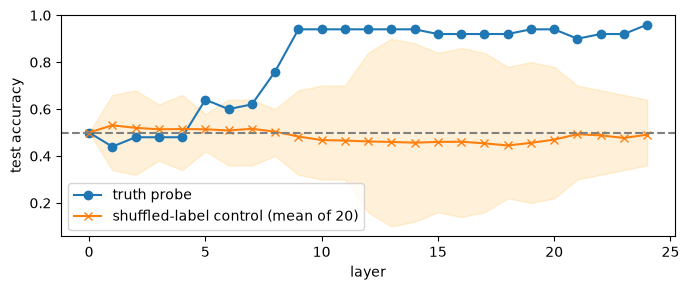

In [4]:
tr, te = (data.split == "train").values, (data.split == "test").values
y = data.label.values
N_PERM = 20                                         # one shuffle can match the labels by luck; use many
perms = [np.random.default_rng(k).permutation(y[tr]) for k in range(N_PERM)]


def probe_acc(X, labels) -> float:
    return LogisticRegression(max_iter=2000, C=0.1).fit(X[tr], labels).score(X[te], y[te])


scores = []
for layer in range(N_LAYERS + 1):
    X = acts[:, layer]
    ctrl = np.array([probe_acc(X, yp) for yp in perms])
    scores.append({"layer": layer, "probe": probe_acc(X, y[tr]), "shuffled_mean": ctrl.mean(),
                   "shuffled_max": ctrl.max(), "p_value": (1 + (ctrl >= probe_acc(X, y[tr])).sum()) / (N_PERM + 1)})
scores = pd.DataFrame(scores)
# Use the EARLIEST layer within 2 points of the best: later layers mostly re-read what is already there,
# and steering works best where the model is still computing with the concept.
best = int(scores[scores.probe >= scores.probe.max() - 0.02].layer.min())
print(f"top accuracy {scores.probe.max():.2f}; earliest layer within 2 points: {best} "
      f"({scores.probe[best]:.2f} on {te.sum()} unseen statements)")
print(scores.iloc[::3].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(scores.layer, scores.probe, marker="o", label="truth probe")
ax.plot(scores.layer, scores.shuffled_mean, marker="x", label="shuffled-label control (mean of 20)")
ax.fill_between(scores.layer, 0.5 - (scores.shuffled_max - 0.5).abs(), scores.shuffled_max, color="orange", alpha=0.15)
ax.axhline(0.5, color="grey", ls="--"); ax.set_xlabel("layer"); ax.set_ylabel("test accuracy"); ax.legend()
plt.tight_layout(); plt.show()

## Step 11. Intervene: push the model along the truth direction

A probe that reads a concept does not prove the model **uses** it. So we take the simplest version of the
direction (mean activation of true statements minus mean of false ones, at the best layer), add a multiple of
it to the residual stream while the model answers "True or False?", and measure the change in its answer.

The behaviour measured is the log-odds of the next token being "True" against "False". If the direction is
causal, adding it should push answers on false statements towards "True", and subtracting it the other way.

In [5]:
direction = acts[tr & (y == 1), best].mean(0) - acts[tr & (y == 0), best].mean(0)
direction = torch.tensor(direction / np.linalg.norm(direction), device=DEVICE, dtype=torch.float32)
typical_norm = float(np.linalg.norm(acts[tr, best], axis=1).mean())
TRUE_ID = tok("True", add_special_tokens=False).input_ids[0]
FALSE_ID = tok("False", add_special_tokens=False).input_ids[0]


def ask(statement: str) -> dict:
    msgs = [{"role": "user", "content": f"Is this statement true or false? Answer with one word, True or False.\n{statement}"}]
    text = tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    return tok(text, return_tensors="pt").to(DEVICE)


@torch.no_grad()
def true_log_odds(statement: str, alpha: float) -> float:
    """log P(True) - log P(False) for the next token, with alpha * direction added after layer `best`."""
    def hook(module, inputs, output):
        h = output[0] if isinstance(output, tuple) else output
        h = h + alpha * typical_norm * 0.1 * direction             # alpha is in units of 10% of a typical norm
        return (h,) + tuple(output[1:]) if isinstance(output, tuple) else h
    handle = model.model.layers[best - 1].register_forward_hook(hook)   # hidden_states[best] = output of layer best-1
    try:
        logits = model(**ask(statement)).logits[0, -1].float()
    finally:
        handle.remove()
    lp = torch.log_softmax(logits, -1)
    return float(lp[TRUE_ID] - lp[FALSE_ID])


test = data[te].reset_index(drop=True)
alphas = [-4, -2, 0, 2, 4]
grid = pd.DataFrame([{"label": r.label, "alpha": a, "log_odds_true": true_log_odds(r.text, a)}
                     for r in test.itertuples() for a in alphas])
base = grid[grid.alpha == 0]
print(f"model's own True/False accuracy (alpha=0): {((base.log_odds_true > 0) == (base.label == 1)).mean():.2f}")
grid.groupby(["label", "alpha"]).log_odds_true.mean().unstack("alpha").round(2)

model's own True/False accuracy (alpha=0): 0.94


alpha,-4,-2,0,2,4
label,,,,,
0,-3.61,-1.96,-1.62,-0.68,2.55
1,-2.92,0.12,2.86,4.25,4.49


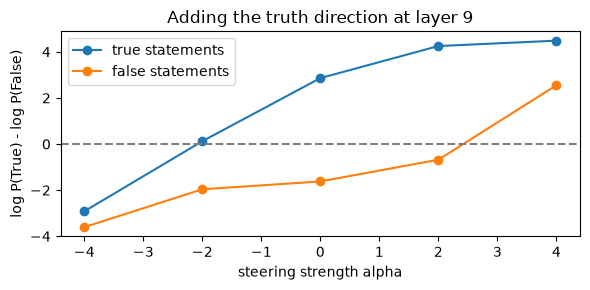

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
for lab, name in [(1, "true statements"), (0, "false statements")]:
    g = grid[grid.label == lab].groupby("alpha").log_odds_true.mean()
    ax.plot(g.index, g.values, marker="o", label=name)
ax.axhline(0, color="grey", ls="--"); ax.set_xlabel("steering strength alpha"); ax.set_ylabel("log P(True) - log P(False)")
ax.legend(); ax.set_title(f"Adding the truth direction at layer {best}"); plt.tight_layout(); plt.show()

## Step 12. Write-up

**Findings from the saved run (15 October 2026, Qwen2.5-0.5B-Instruct, RTX 3080):**

1. **Truth is linearly readable from layer 9 onwards.** Probe accuracy on 50 statements about unseen
   countries jumps from 60% at layer 6 to 94% at layer 9, and stays at 90-96% to the last layer. Layers 0-3 are
   at chance: the concept is computed, not present in the raw words.
2. **The control nearly fooled us.** A single shuffled-label probe scored 84% at layer 12. Twenty shuffles
   averaged 44-51%, so that 84% was luck. Every layer from 9 on beat all 20 shuffles (p = 0.05, the smallest
   p-value 20 shuffles can give; run more shuffles for a finer one). **Never trust one control run.**
3. **The direction is causal.** Adding it at layer 9 moves the model's answer steadily for both kinds of
   statement: on false statements the log-odds of "True" go from -3.61 (pushed away) through -1.62 (no push) to
   +2.55 (pushed towards), which flips the answer; true statements move from -2.92 to +4.49. In an earlier
   version that steered at the final layer, true statements lost confidence whichever way they were pushed,
   which is why we steer at the earliest strong layer.
4. **The model itself answers 94% correctly** with no push, so the probe matches its own knowledge.

How to read results like these, in the order a reviewer would:

1. **Is the concept readable?** Probe accuracy on unseen countries, by layer. Concepts usually become readable
   in the middle layers, not the first.
2. **Is the probe real?** The shuffled-label control should sit near 50% at every layer.
3. **Is it causal?** If the log-odds of "True" rise with alpha for both true and false statements, the direction
   changes behaviour, not just correlates with it. A flat line would mean the probe reads something the model
   does not use for this answer.

**Limitations:** one simple kind of statement; a 0.5B model; a difference-of-means direction (sparse
autoencoders and transcoders find many directions at once and are far richer); steering added at every token
position.

**Next experiments:** test whether the probe generalises to a different kind of statement (Anthropic's research
directions ask exactly this: do probes trained on one distribution work on another?); compare with the
circuit-tracer library's attribution graphs on Gemma-2 2B, which its tutorial notebook runs on a free Colab GPU.